<a href="https://colab.research.google.com/github/pcbassani/variavel-precipitacao-06/blob/main/dados_analise_precipitacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1 bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
# 2 carregar arquivos

#from google.colab import files
#enviado = files.upload()
#arquivo = list(enviado.keys())[0]

# Alternativa: ler direto do GitHub (troque USUARIO/REPOSITORIO)
arquivo = "https://raw.githubusercontent.com/pcbassani/variavel-precipitacao-06/main/precipitacao_diaria_2025.xlsx"

#df = pd.read_excel(arquivo, usecols="A:D")
#df["data"] = pd.to_datetime(df["data"])
#df.head()

In [ ]:
print("teste de novooooo")

In [ ]:
# 2 carregar arquivos

from google.colab import files
enviado = files.upload()
arquivo = list(enviado.keys())[0]

# Alternativa: ler direto do GitHub (troque USUARIO/REPOSITORIO)
# arquivo = "https://raw.githubusercontent.com/USUARIO/REPOSITORIO/main/precipitacao_diaria_2025.xlsx"

df = pd.read_excel(arquivo, usecols="A:D")
df["data"] = pd.to_datetime(df["data"])
df.head()

Saving precipitacao_diaria_2025 (1).xlsx to precipitacao_diaria_2025 (1).xlsx


,data,precip_min_mm,precip_med_mm,precip_max_mm
0,2025-01-01,0.0,0.0,0.0
1,2025-01-02,7.9,19.2,36.7
2,2025-01-03,0.0,0.0,0.0
3,2025-01-04,0.0,0.0,0.0
4,2025-01-05,4.5,8.3,17.7


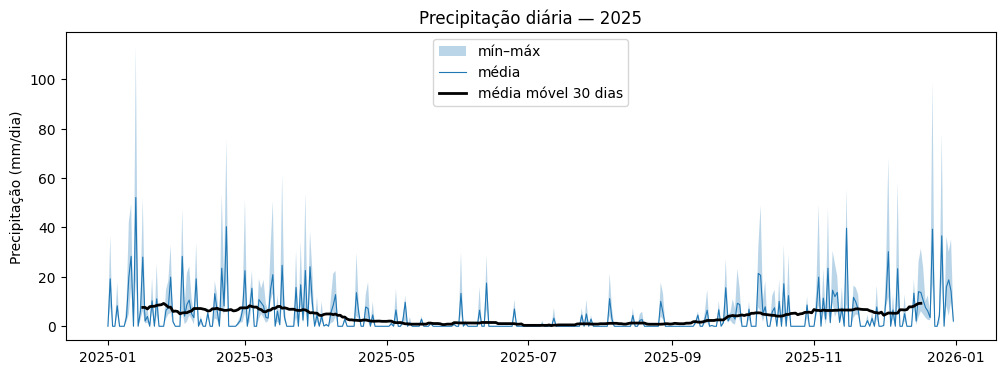

In [ ]:
# 4 grafico da serie

plt.figure(figsize=(12, 4))
plt.fill_between(df["data"], df["precip_min_mm"], df["precip_max_mm"], alpha=0.3, label="mín–máx")
plt.plot(df["data"], df["precip_med_mm"], lw=0.8, label="média")
plt.plot(df["data"], df["precip_med_mm"].rolling(30, center=True).mean(),
         lw=2, color="black", label="média móvel 30 dias")
plt.ylabel("Precipitação (mm/dia)")
plt.title("Precipitação diária — 2025")
plt.legend()
plt.show()

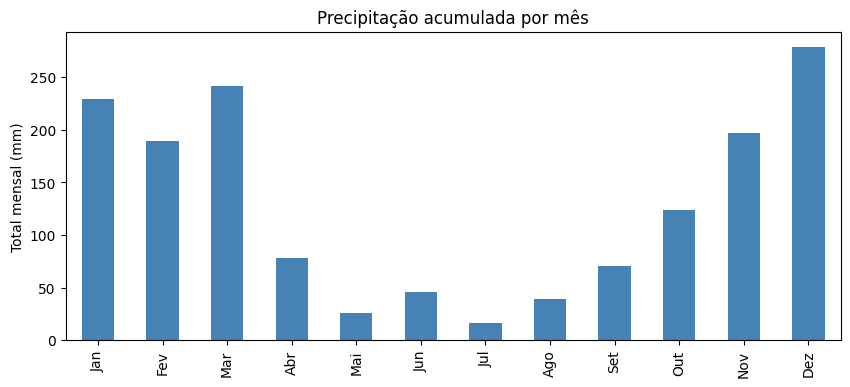

,precip_med_mm
Jan,228.9
Fev,189.8
Mar,242.0
Abr,77.8
Mai,26.3
Jun,45.6
Jul,16.6
Ago,39.1
Set,70.6
Out,123.5


In [ ]:
# 5 totais mensais

meses = ["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"]
mensal = df.groupby(df["data"].dt.month)["precip_med_mm"].sum()
mensal.index = meses

mensal.plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.ylabel("Total mensal (mm)")
plt.title("Precipitação acumulada por mês")
plt.show()
mensal.round(1)

Regressão linear: inclinação = -0.0013 mm/dia por dia, p = 0.727
Mann-Kendall:     tau = -0.003, p = 0.938

➡ Não há tendência estatisticamente significativa


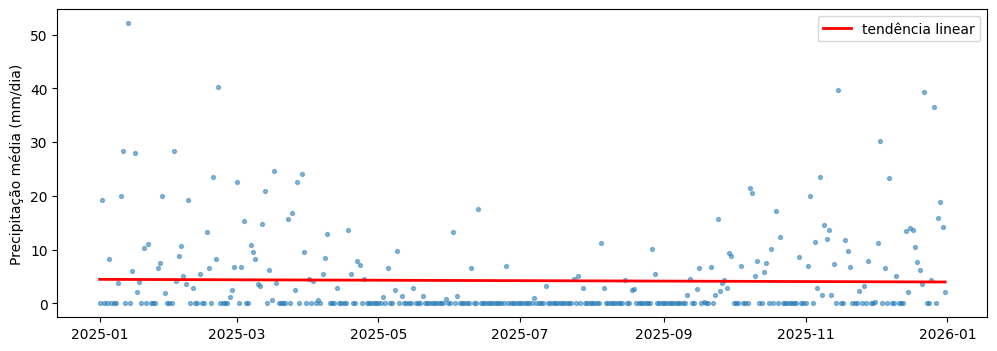

In [ ]:
# 6 tendencia de aumento

dias = np.arange(len(df))
y = df["precip_med_mm"]

reg = stats.linregress(dias, y)
tau, p_mk = stats.kendalltau(dias, y)   # equivale ao teste de Mann-Kendall

print(f"Regressão linear: inclinação = {reg.slope:.4f} mm/dia por dia, p = {reg.pvalue:.3f}")
print(f"Mann-Kendall:     tau = {tau:.3f}, p = {p_mk:.3f}\n")

if p_mk < 0.05:
    print("➡ Tendência significativa de", "AUMENTO" if tau > 0 else "DIMINUIÇÃO")
else:
    print("➡ Não há tendência estatisticamente significativa")

plt.figure(figsize=(12, 4))
plt.scatter(df["data"], y, s=8, alpha=0.5)
plt.plot(df["data"], reg.intercept + reg.slope * dias, color="red", lw=2, label="tendência linear")
plt.ylabel("Precipitação média (mm/dia)")
plt.legend()
plt.show()

In [ ]:
# 7 maior volume

dia_max = df.loc[df["precip_max_mm"].idxmax()]
dia_med = df.loc[df["precip_med_mm"].idxmax()]
print(f"Dia com maior precipitação máxima: {dia_max['data']:%d/%m/%Y} ({dia_max['precip_max_mm']} mm)")
print(f"Dia com maior precipitação média:  {dia_med['data']:%d/%m/%Y} ({dia_med['precip_med_mm']} mm)")
print(f"Mês mais chuvoso: {mensal.idxmax()} ({mensal.max():.1f} mm)")
print(f"Mês mais seco:    {mensal.idxmin()} ({mensal.min():.1f} mm)")

estacoes = {12:"Verão",1:"Verão",2:"Verão",3:"Outono",4:"Outono",5:"Outono",
            6:"Inverno",7:"Inverno",8:"Inverno",9:"Primavera",10:"Primavera",11:"Primavera"}
por_estacao = df.groupby(df["data"].dt.month.map(estacoes))["precip_med_mm"].sum()
print("\nTotal por estação (hemisfério sul):")
print(por_estacao.round(1).sort_values(ascending=False))

Dia com maior precipitação máxima: 13/01/2025 (113.3 mm)
Dia com maior precipitação média:  13/01/2025 (52.1 mm)
Mês mais chuvoso: Dez (279.0 mm)
Mês mais seco:    Jul (16.6 mm)

Total por estação (hemisfério sul):
data
Verão        697.7
Primavera    390.7
Outono       346.1
Inverno      101.3
Name: precip_med_mm, dtype: float64


In [ ]:
# 8 dias mais chuvoso

df.nlargest(10, "precip_med_mm")

,data,precip_min_mm,precip_med_mm,precip_max_mm
12,2025-01-13,18.7,52.1,113.3
51,2025-02-21,18.2,40.3,75.8
318,2025-11-15,8.9,39.7,55.5
355,2025-12-22,17.4,39.3,99.1
359,2025-12-26,18.2,36.6,78.0
336,2025-12-03,11.8,30.2,68.2
10,2025-01-11,15.9,28.3,49.5
32,2025-02-02,6.6,28.3,47.5
15,2025-01-16,6.3,28.0,51.9
75,2025-03-17,8.5,24.7,61.4
